# MDC_51006_EP - Foundations of Machine Learning - Lab 7

The goal of this lab is
- to explore some dimension reduction algorithms,
- to test the most classical clustering algorithms.

Once again, we will use the German credit dataset!

In [ ]:
!wget -nc https://raw.githubusercontent.com/IBM/monitor-wml-model-with-watson-openscale/master/data/german_credit_data_biased_training.csv

rm: cannot remove 'german_credit_data_biased_training.csv': No such file or directory
--2025-11-05 10:05:04--  https://raw.githubusercontent.com/IBM/monitor-wml-model-with-watson-openscale/master/data/german_credit_data_biased_training.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 689622 (673K) [text/plain]
Saving to: ‘german_credit_data_biased_training.csv’

german_credit_data_ 100%[===================>] 673.46K  --.-KB/s    in 0.04s   

2025-11-05 10:05:05 (15.4 MB/s) - ‘german_credit_data_biased_training.csv’ saved [689622/689622]



In [ ]:
import polars as pl

In [ ]:
german_credit = pl.read_csv("german_credit_data_biased_training.csv")

In [ ]:
import seaborn.objects as so

In [ ]:
import polars.selectors as cs
string_columns = german_credit.select(cs.string()).columns
numerical_columns = german_credit.select(cs.numeric()).columns

In [ ]:
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

In [ ]:
categorical_features = string_columns.copy()
categorical_features.remove('Risk')
categorical_transformer = Pipeline(steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
numerical_transformer = Pipeline(steps=[
        ('scaler', StandardScaler())
    ])

preprocessor = ColumnTransformer(
        transformers=[
            ('cat', categorical_transformer, categorical_features),
            ('num', numerical_transformer, numerical_columns)
        ],
        remainder='passthrough',
        force_int_remainder_cols=False
    )

In [ ]:
X = german_credit.drop('Risk')
y = german_credit['Risk']
LoanAmount = X['LoanAmount']

## Encoding and Dimension Reduction

We can use the `preprocessor`pipeline we have used before to transform the dataset into a *dataset of vectors*, i.e. a matrix.

In [ ]:
X_mat = preprocessor.fit_transform(X)

**Question** What is the dimension of those vectors?

**Answer** Using the `shape`attribute:

In [ ]:
X_mat.shape

(5000, 60)

We see that the dimension of those vectors is 60.

---

This dimension is (much) larger than 2 and thus it is hard to visualize our dataset with a single plot.

The most classical dimension reduction method is probably the Principal Component Analysis (PCA). It is available in scikit learn with

In [ ]:
from sklearn.decomposition import PCA

In [ ]:
pca = PCA(n_components=2)
X_PCA = pca.fit_transform(X_mat)

The resulting matrix has only 2 columns (a collection of vector of dimension 2) which can be visualized:

In [ ]:
df_PCA = pl.DataFrame({ 'PC1': X_PCA[:,0], 'PC2': X_PCA[:,1], 'Risk': y})

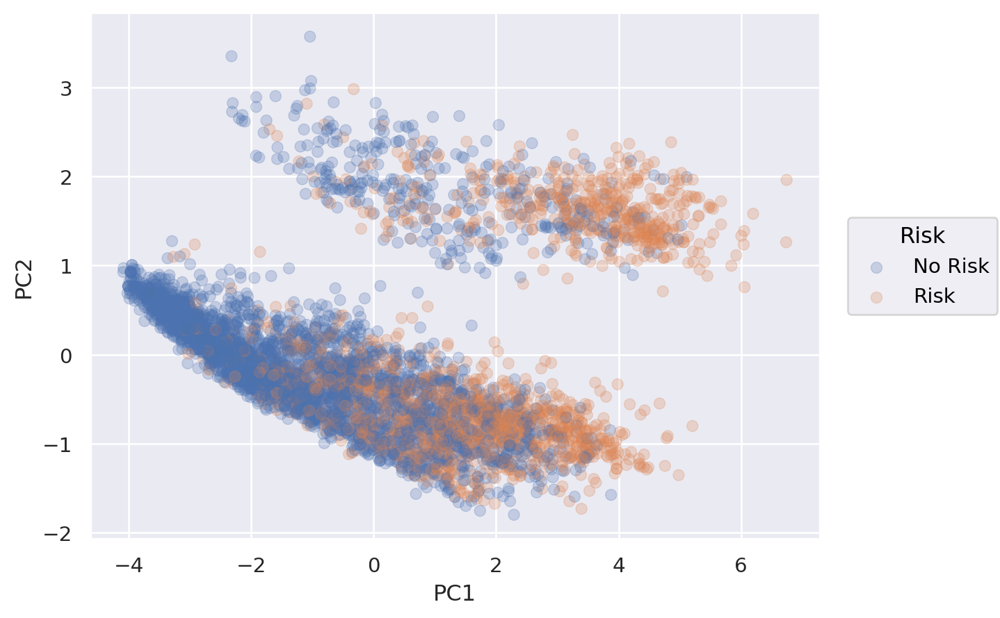

In [ ]:
so.Plot(df_PCA, x='PC1', y='PC2', color='Risk').add(so.Dot(alpha=.25))

**Question** How different is the picture if you use the TSNE algorithm (included in scikit learn) or the UMAP one.

Please store the result of the TSNE in `X_TSNE` as this name is used below. In the meantime, we let


In [ ]:
X_TSNE = X_PCA

so that the notebook runs...

**Answer**

In [ ]:
from sklearn.manifold import TSNE

In [ ]:
X_TSNE = TSNE(n_components=2, learning_rate='auto',

                  init='random', perplexity=3).fit_transform(X_mat)

In [ ]:
df_TSNE = pl.DataFrame({ 'PC1': X_TSNE[:,0], 'PC2': X_TSNE[:,1], 'Risk': y})

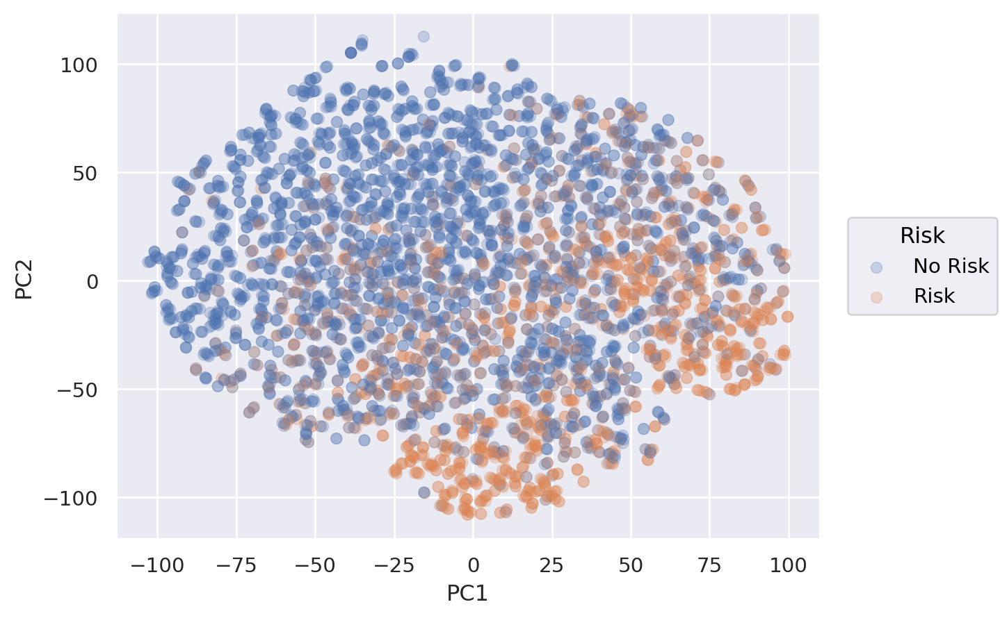

In [ ]:
so.Plot(df_TSNE, x='PC1', y='PC2', color='Risk').add(so.Dot(alpha=.25))

In [ ]:
!uv pip install umap-learn

Using Python 3.12.12 environment at: /usr
Audited 1 package in 278ms


In [ ]:
from umap import UMAP

In [ ]:
X_UMAP = UMAP(n_components=2).fit_transform(X_mat)

In [ ]:
df_UMAP = pl.DataFrame({ 'PC1': X_UMAP[:,0], 'PC2': X_UMAP[:,1], 'Risk': y})

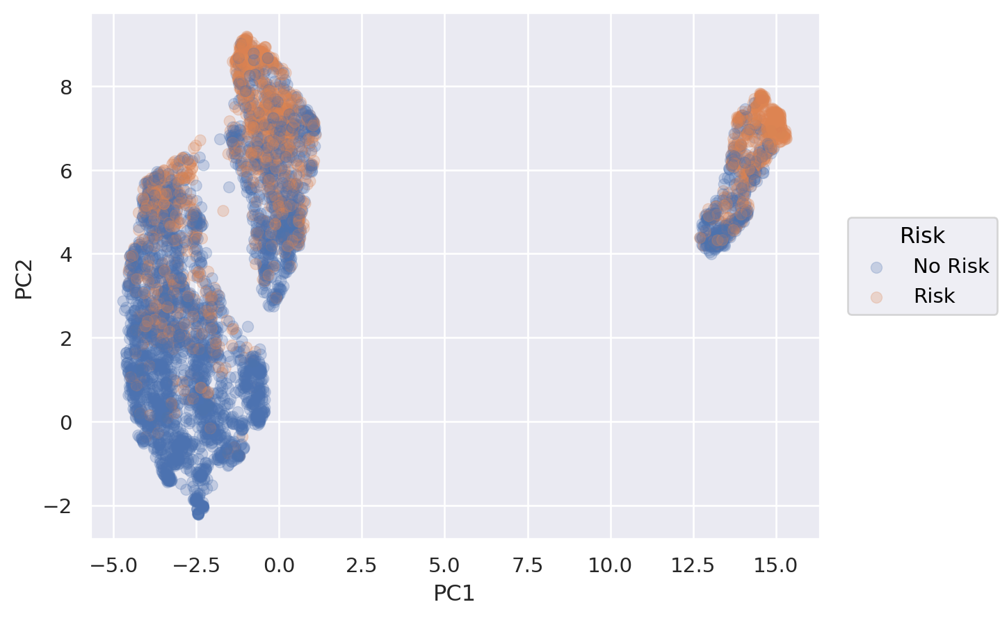

In [ ]:
so.Plot(df_UMAP, x='PC1', y='PC2', color='Risk').add(so.Dot(alpha=.25))

---

**Question** Which representation is the best?

**Answer** None... As we have absolutely no idea how to use them properly...

---





## Clustering

We are going now to explore the most classical clustering algorithms starting with the k-means algorithm.

Once again relying on scikit learn, we obtain

In [ ]:
from sklearn.cluster import KMeans

In [ ]:
kmeans_PCA = KMeans(n_clusters=8, random_state=0, n_init="auto").fit(X_PCA)

We can now look at the obtained labels

In [ ]:
kmeans_PCA.labels_

array([5, 1, 1, ..., 3, 5, 1], dtype=int32)

or better visualize them with

In [ ]:
df_PCA = df_PCA.with_columns(pl.Series('Cluster', kmeans_PCA.labels_))

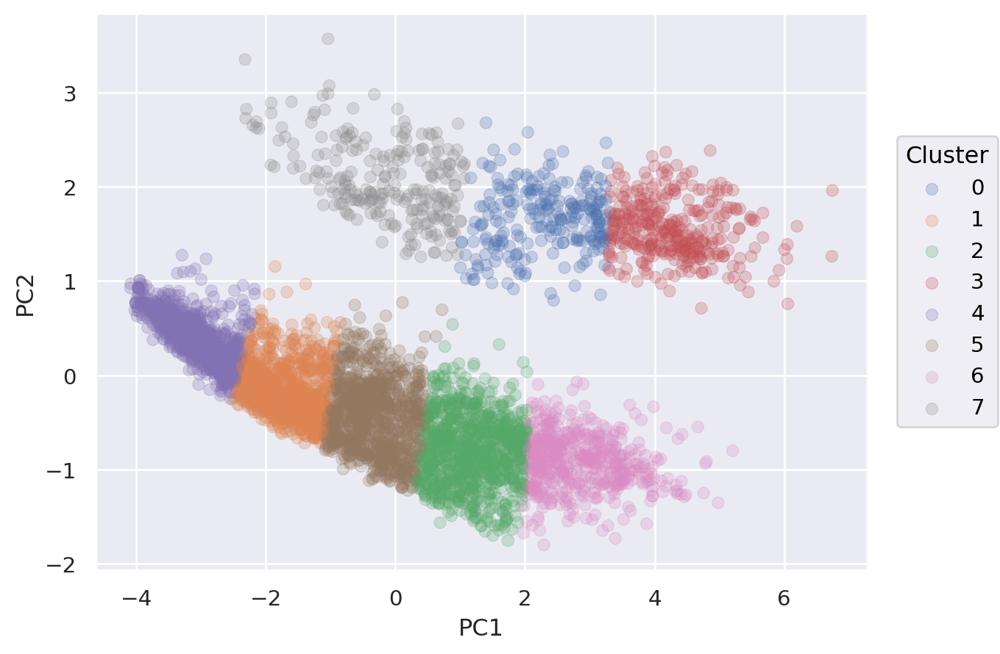

In [ ]:
so.Plot(df_PCA, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal())

**Question** What is the result if we visualize the clustering using the TSNE representation or if we use the TSNE representation to do the clustering ?

**Answer**

In [ ]:
df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', kmeans_PCA.labels_))

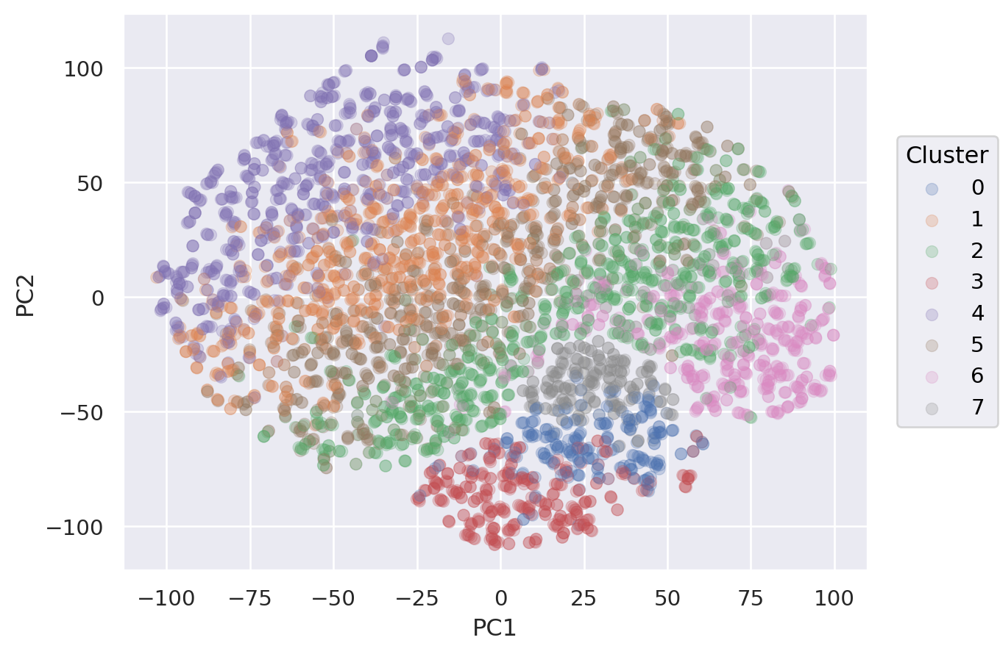

In [ ]:
so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal())

In [ ]:
kmeans_TSNE = KMeans(n_clusters=8, random_state=0, n_init="auto").fit(X_TSNE)

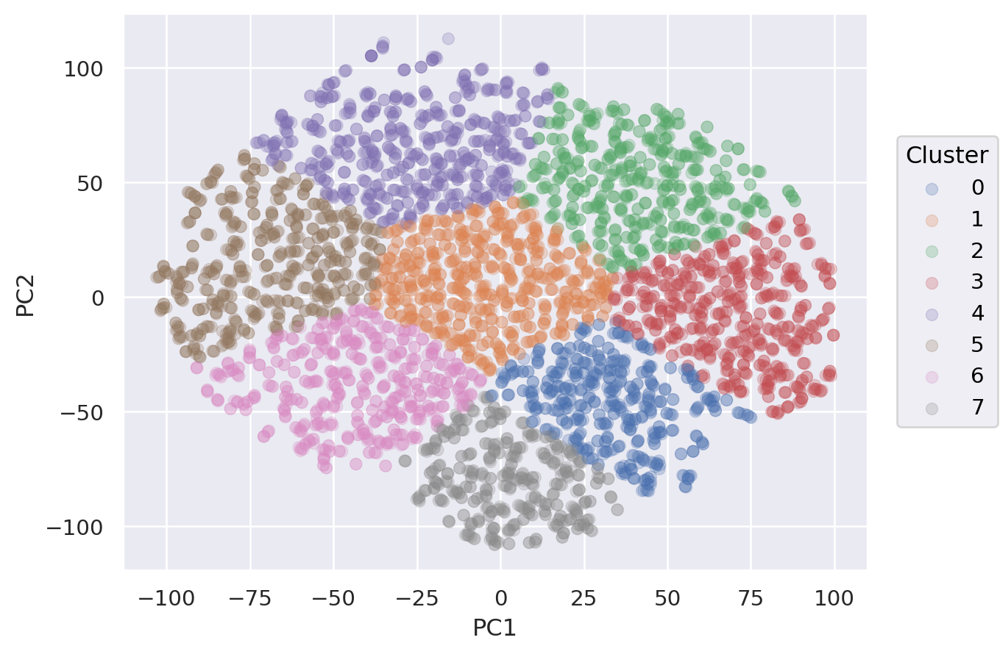

In [ ]:
df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', kmeans_TSNE.labels_))
so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal())


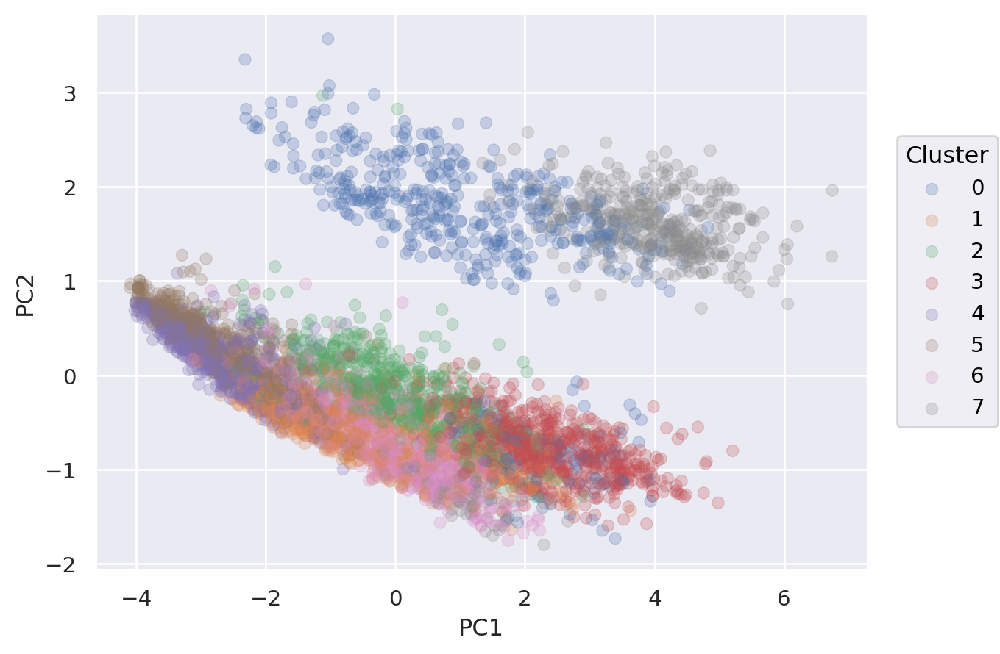

In [ ]:
df_PCA = df_PCA.with_columns(pl.Series('Cluster', kmeans_TSNE.labels_))
so.Plot(df_PCA, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal())

---

**Question** How to visualize the agreement between the two clustering?

**Answer**

In [ ]:
labels_df = pl.DataFrame({'PCA': kmeans_PCA.labels_, 'TSNE': kmeans_TSNE.labels_})

In [ ]:
label_count_df = labels_df.group_by(['PCA','TSNE']).len().sort(['PCA', 'TSNE']).with_columns((pl.col('len')/ pl.col('len').sum()).alias('prop'))

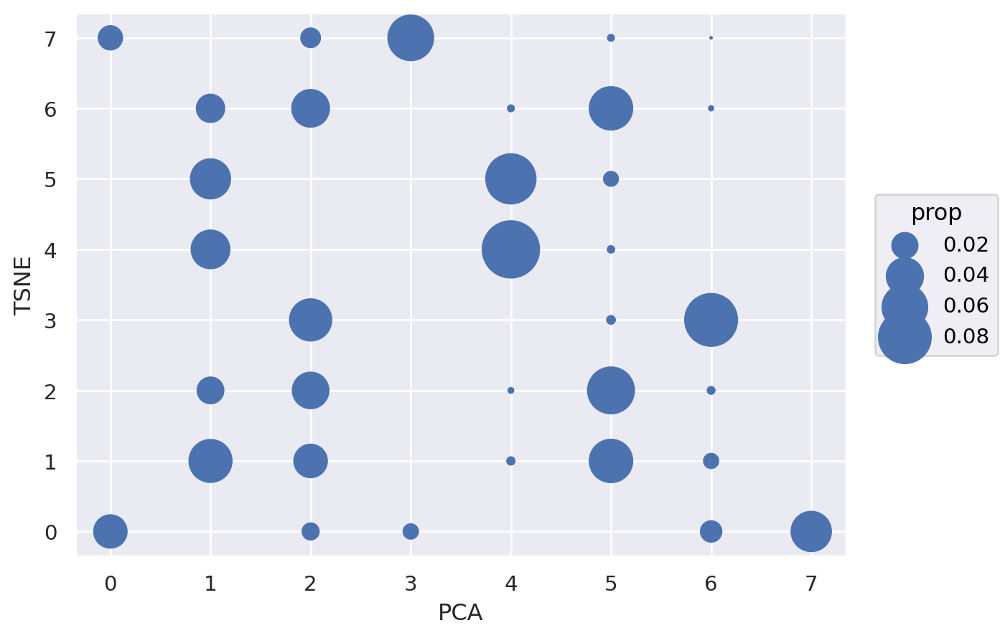

In [ ]:
so.Plot(label_count_df, x='PCA', y='TSNE', pointsize='prop').add(so.Dot()).scale(pointsize=(0,30))

---

We can apply the same clustering algorithm 9 times with

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import seaborn as sns
sns.set()
fig = plt.figure(figsize=(10,10))



<Figure size 1000x1000 with 0 Axes>

In [ ]:
for i in range(9):
  kmeans = KMeans(n_clusters=8, n_init="auto").fit(X_TSNE)
  df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', kmeans.labels_))
  ax = fig.add_subplot(3,3,i+1)
  so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal()).layout(size=(5,3)).on(ax).show()

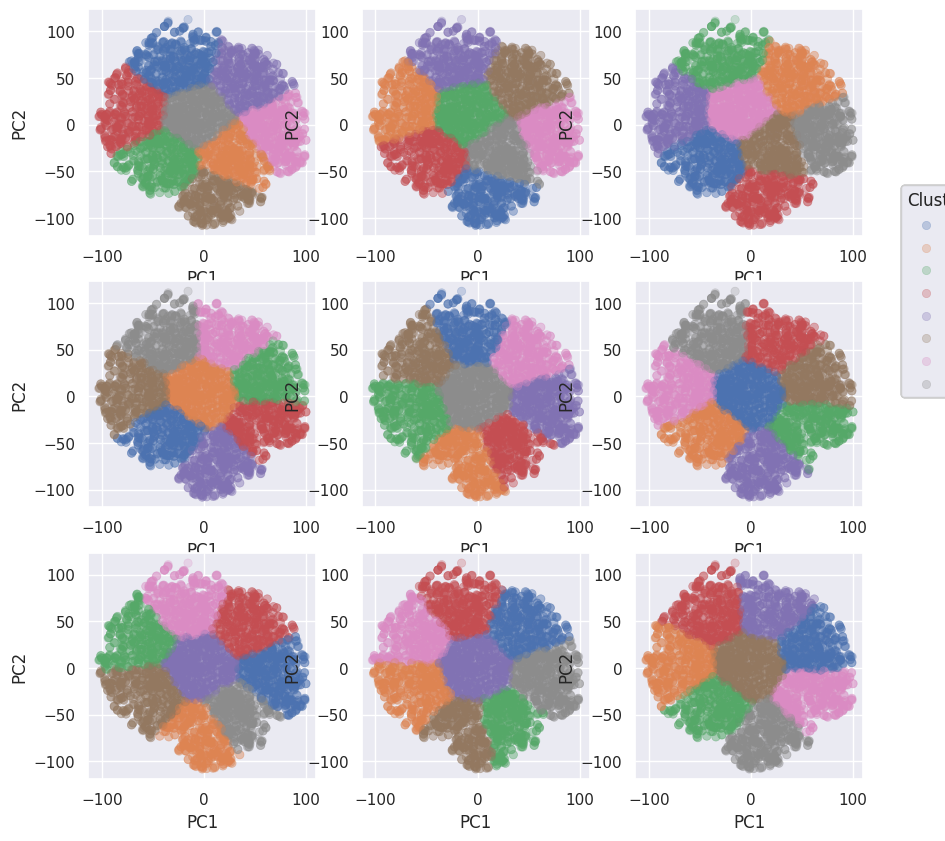

In [ ]:
fig

**Question** Why are the 9 results different?

**Answer** The k-means algorithm includes a random initialization and thus may lead to different results each time it is excecuted!

---

**Question** How do the clustering evolves when the number of components varies from 1 to 9 ?

**Answer**

In [ ]:
fig = plt.figure(figsize=(10,10))

<Figure size 1000x1000 with 0 Axes>

In [ ]:
for i in range(9):
  kmeans = KMeans(n_clusters=i+1, n_init="auto").fit(X_TSNE)
  df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', kmeans.labels_))
  ax = fig.add_subplot(3,3,i+1)
  so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal()).layout(size=(5,3)).on(ax).show()

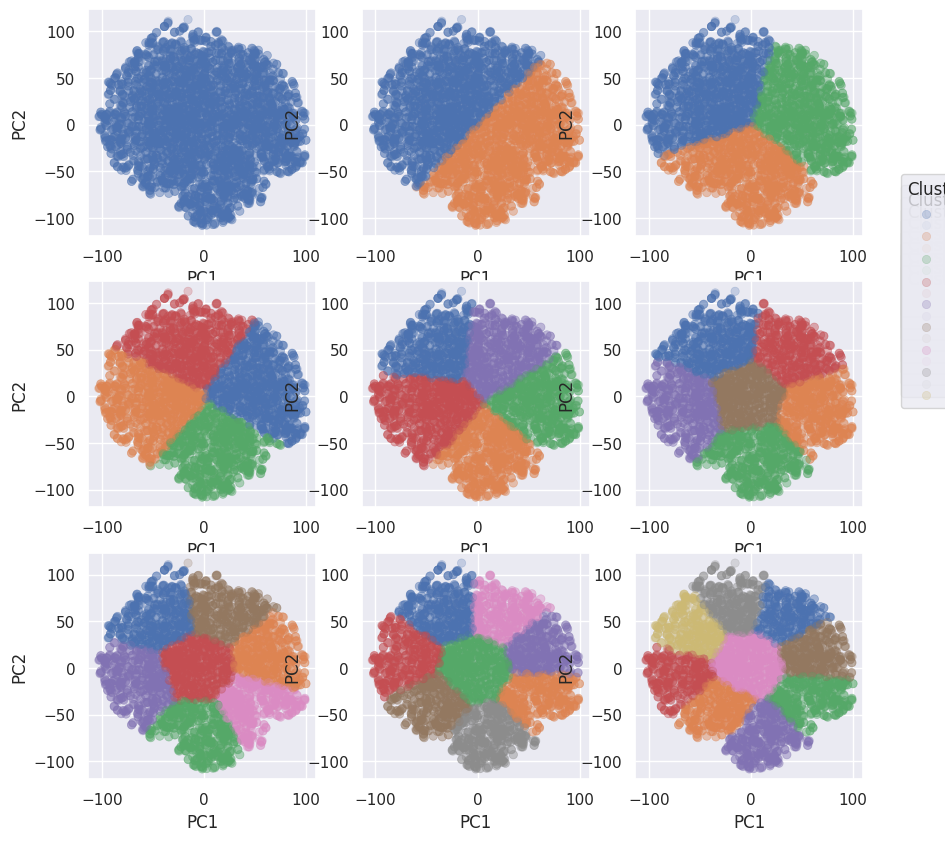

In [ ]:
fig

---

A hierachical clustering strategy is also possible with Scikit Learn, for instance with

In [ ]:
from sklearn.cluster import AgglomerativeClustering

In [ ]:
clustering_TSNE = AgglomerativeClustering(n_clusters=8).fit(X_TSNE)

In [ ]:
clustering_TSNE.labels_

array([4, 2, 2, ..., 0, 4, 4])

In [ ]:
df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', clustering_TSNE.labels_))

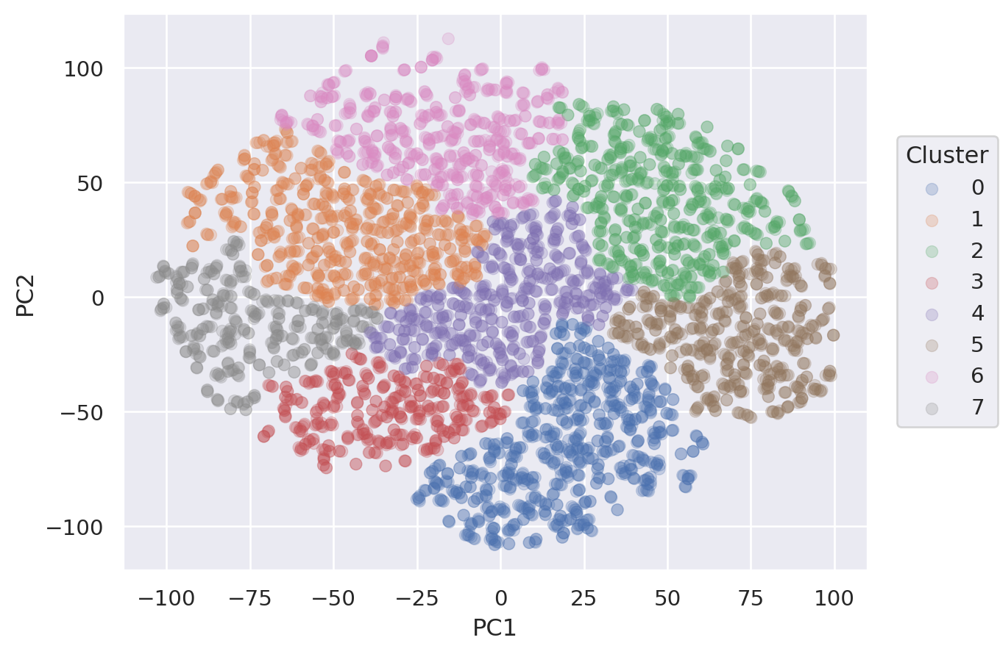

In [ ]:
so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal())

---

**Question** Compare the results of this algoritm with the ward, average, complete and single linkage method.

**Answer**

In [ ]:
fig = plt.figure(figsize=(10,10))

<Figure size 1000x1000 with 0 Axes>

In [ ]:
for i, linkage_method in enumerate(['ward', 'average', 'complete', 'single']):
  clustering_TSNE = AgglomerativeClustering(n_clusters=8, linkage=linkage_method).fit(X_TSNE)
  df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', clustering_TSNE.labels_))
  ax = fig.add_subplot(2,2,i+1)
  so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal()).label(title=linkage_method).on(ax).show()

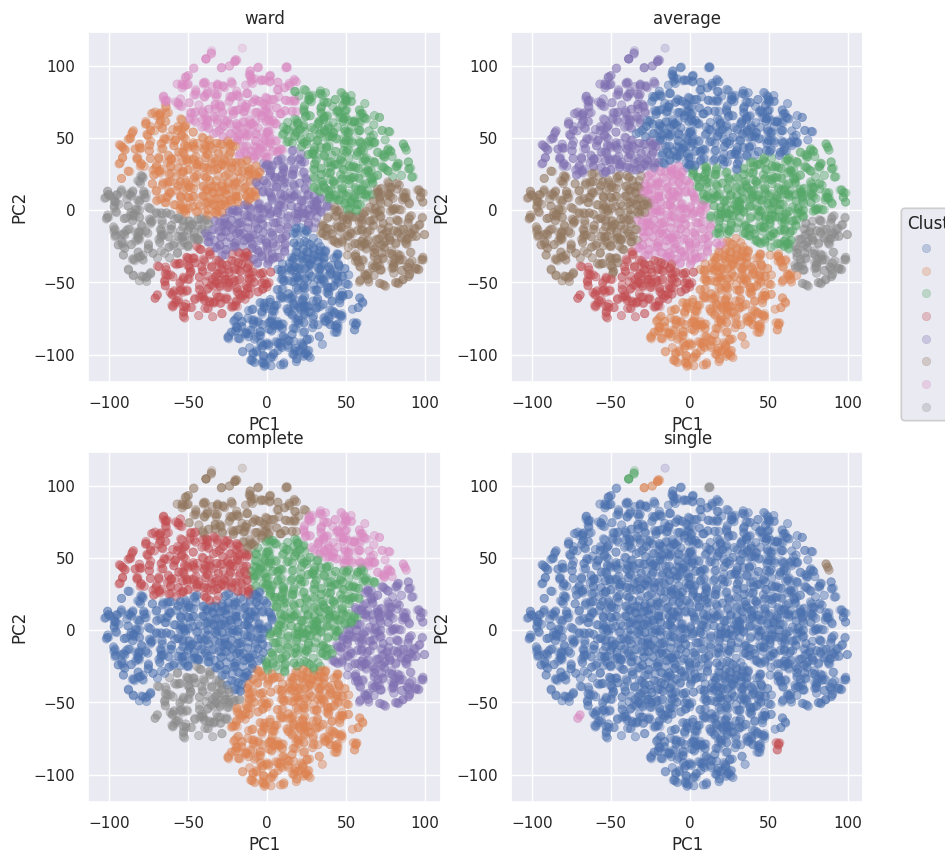

In [ ]:
fig

---

It exists a better implementation of the hierarchical clustering algorithm  in the `fastcluster` library. It works as follows

In [ ]:
!uv pip install fastcluster

Using Python 3.12.12 environment at: /usr
Resolved 2 packages in 226ms
Prepared 1 package in 59ms
Installed 1 package in 5ms
 + fastcluster==1.3.0


In [ ]:
from fastcluster import linkage

In [ ]:
X_linkage = linkage(X_TSNE, method='ward', metric='euclidean')

In [ ]:
from scipy.cluster.hierarchy import dendrogram, fcluster

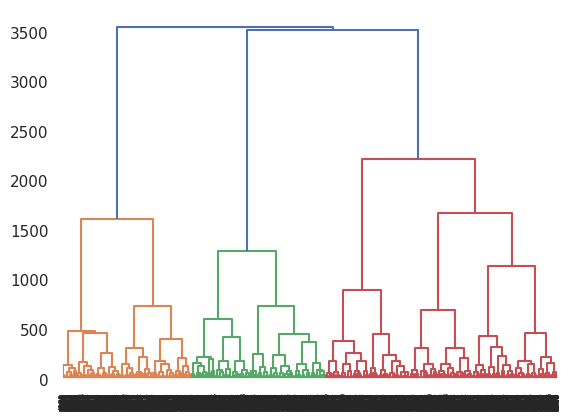

In [ ]:
dn = dendrogram(X_linkage)

In [ ]:
labels_ = fcluster(X_linkage, t=8, criterion='maxclust')

In [ ]:
df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', labels_))

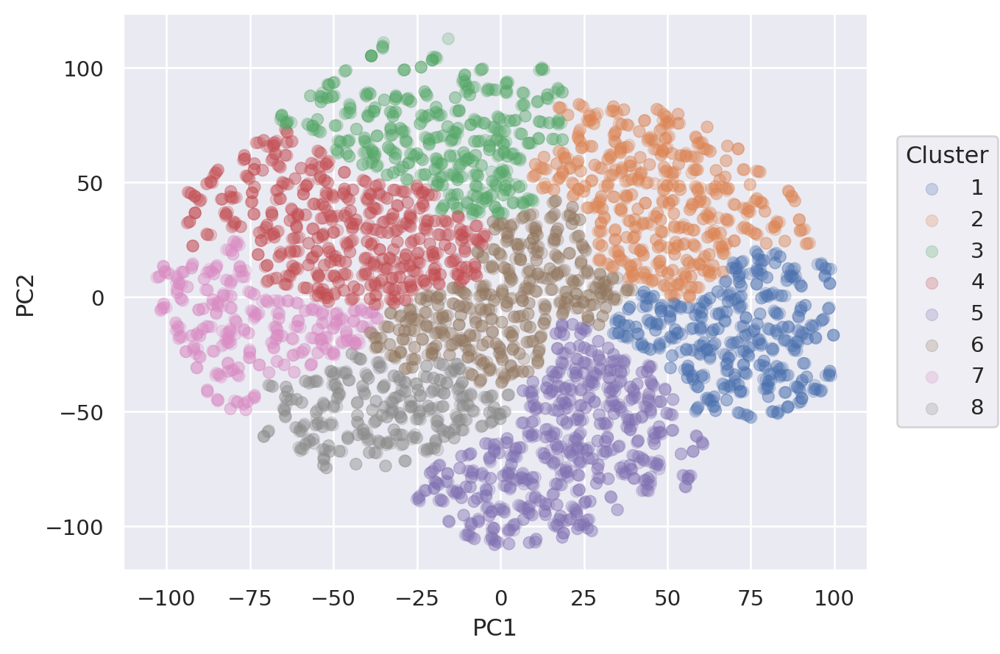

In [ ]:
so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal())

In [ ]:
fig = plt.figure(figsize=(10,15))
fig.clf()

<Figure size 1000x1500 with 0 Axes>

Note in particular that the number of components is chosen after a full tree is build, so that we can test efficiently several choices for this number of components

In [ ]:
for i, linkage_method in enumerate(['ward', 'average', 'complete', 'single']):
  X_linkage = linkage(X_TSNE, method=linkage_method, metric='euclidean')
  for j in range(1,10):
    labels_ = fcluster(X_linkage, t=j, criterion='maxclust')
    df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', labels_))
    ax = fig.add_subplot(10,4, 1+i+4*(j-1) )
    so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal()).label(title=linkage_method).on(ax).show()

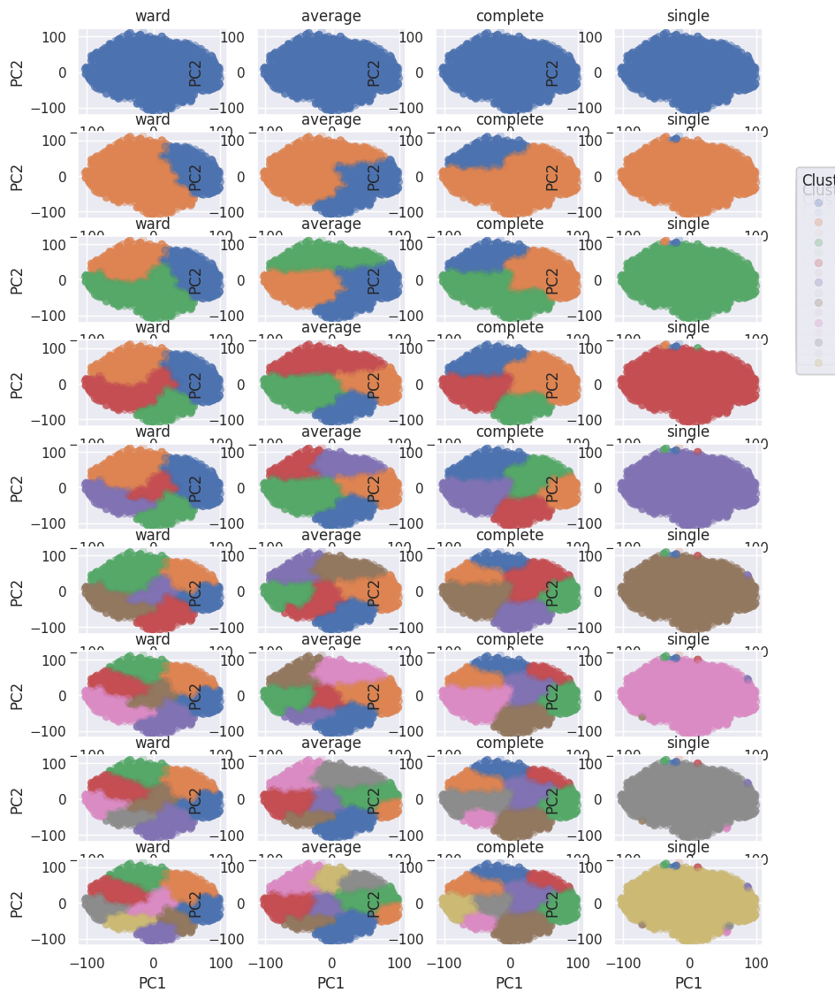

In [ ]:
fig

**Question** What about the HDSCAN method ?

You can use $.1$ for the value of alpha.

**Answer**

In [ ]:
from sklearn.cluster import HDBSCAN

In [ ]:
clustering_HDBSCAN = HDBSCAN(alpha=.1).fit(X_TSNE)

In [ ]:
clustering_HDBSCAN.labels_

array([456, 236, 304, ..., 186, 348, 434])

In [ ]:
df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', clustering_HDBSCAN.labels_))

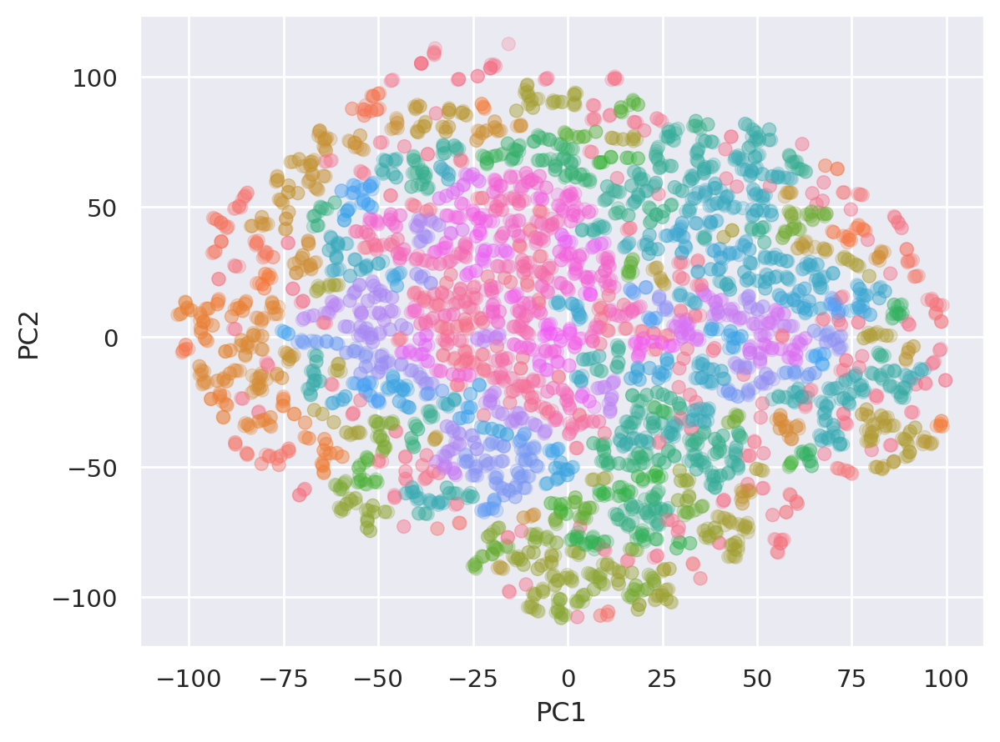

In [ ]:
so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25), legend=False).scale(color=so.Nominal())

**Question** Is there a better choice for the parameter alpha ?

**Answer**

In [ ]:
fig = plt.figure(figsize=(10,10))

<Figure size 1000x1000 with 0 Axes>

In [ ]:
for i, alpha in enumerate([0.01, 0.1, 1, 10]):
  clustering = HDBSCAN(alpha=alpha).fit(X_TSNE)
  df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', clustering.labels_))
  ax = fig.add_subplot(2,2,i+1)
  so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25), legend=False).scale(color=so.Nominal()).label(title=alpha).on(ax).show()

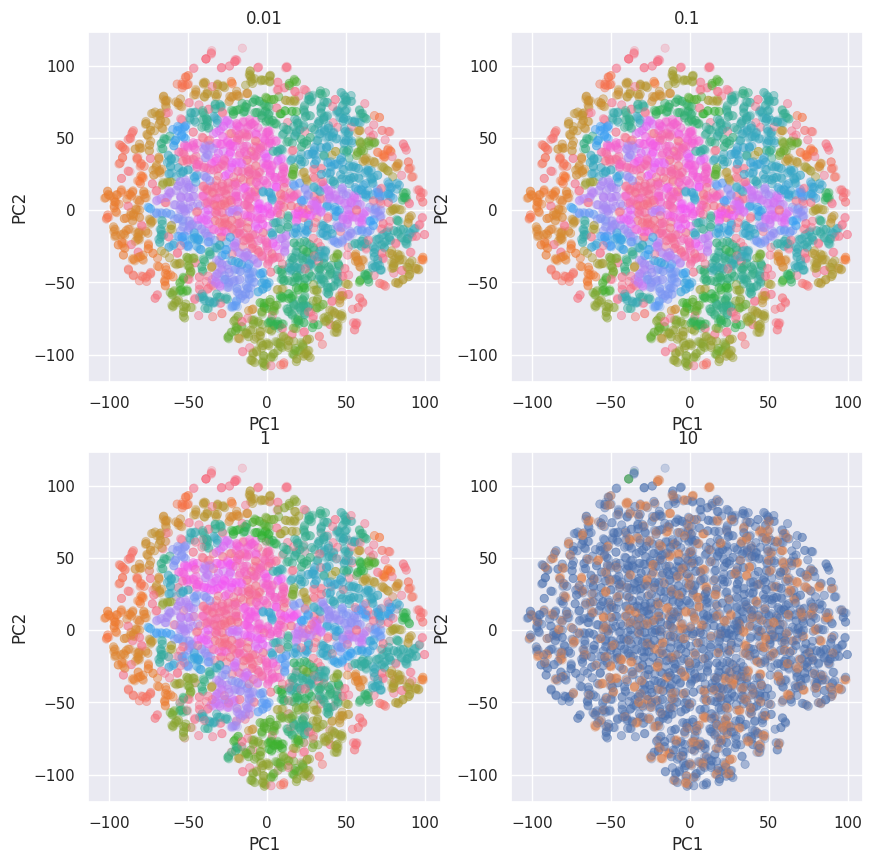

In [ ]:
fig

---

**Question** Can you compare those clustering methods with some metrics proposed by scikit learn?

**Answer**

In [ ]:
from sklearn import metrics

In [ ]:
df_clustering = pl.DataFrame()

In [ ]:
for i in range(9):
  kmeans = KMeans(n_clusters=i+2, n_init="auto").fit(X_TSNE)
  df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', kmeans.labels_))
  df_clustering = pl.concat(
      [df_clustering,
      pl.DataFrame({'name': 'Kmeans', 'n_clusters': i+2, 'silhouette': metrics.silhouette_score(X_TSNE, kmeans.labels_),
                    'calinski_harabasz': metrics.calinski_harabasz_score(X_TSNE, kmeans.labels_),
                    'davies_bouldin': metrics.davies_bouldin_score(X_TSNE, kmeans.labels_)})]
  )

In [ ]:
df_clustering

name,n_clusters,silhouette,calinski_harabasz,davies_bouldin
str,i64,f32,f32,f64
"""Kmeans""",2,0.357559,3184.725342,1.146621
"""Kmeans""",3,0.38228,3964.477783,0.85094
"""Kmeans""",4,0.370271,4280.910156,0.847272
"""Kmeans""",5,0.352514,4302.562012,0.862028
"""Kmeans""",6,0.345013,4257.189941,0.912431
"""Kmeans""",7,0.353504,4277.856445,0.835623
"""Kmeans""",8,0.347903,4372.725586,0.827166
"""Kmeans""",9,0.32582,4159.36377,0.899471
"""Kmeans""",10,0.353752,4471.505859,0.814504


In [ ]:
for i, linkage_method in enumerate(['ward', 'average', 'complete', 'single']):
  X_linkage = linkage(X_TSNE, method=linkage_method, metric='euclidean')
  for j in range(1,10):
    labels_ = fcluster(X_linkage, t=j+1, criterion='maxclust')
    df_clustering = pl.concat(
      [df_clustering,
      pl.DataFrame({'name': 'Hierarchical_'+linkage_method, 'n_clusters': j+2, 'silhouette': metrics.silhouette_score(X_TSNE, labels_),
                    'calinski_harabasz': metrics.calinski_harabasz_score(X_TSNE, labels_),
                    'davies_bouldin': metrics.davies_bouldin_score(X_TSNE, labels_)})]
  )

In [ ]:
df_clustering

name,n_clusters,silhouette,calinski_harabasz,davies_bouldin
str,i64,f32,f32,f64
"""Kmeans""",2,0.357559,3184.725342,1.146621
"""Kmeans""",3,0.38228,3964.477783,0.85094
"""Kmeans""",4,0.370271,4280.910156,0.847272
"""Kmeans""",5,0.352514,4302.562012,0.862028
"""Kmeans""",6,0.345013,4257.189941,0.912431
…,…,…,…,…
"""Hierarchical_single""",7,-0.029574,20.353909,0.616799
"""Hierarchical_single""",8,-0.245588,18.90991,0.632471
"""Hierarchical_single""",9,-0.339283,19.618853,0.636029


In [ ]:
for i, alpha in enumerate([0.01, 0.05, 0.1, 0.5, 1, 5, 10]):
  clustering = HDBSCAN(alpha=alpha).fit(X_TSNE)
  df_clustering = pl.concat(
      [df_clustering,
      pl.DataFrame({'name': 'HDBSCAN', 'n_clusters': len(set(clustering.labels_)),
                    'silhouette': metrics.silhouette_score(X_TSNE, clustering.labels_),
                    'calinski_harabasz': metrics.calinski_harabasz_score(X_TSNE, clustering.labels_),
                    'davies_bouldin': metrics.davies_bouldin_score(X_TSNE, clustering.labels_)})]
  )

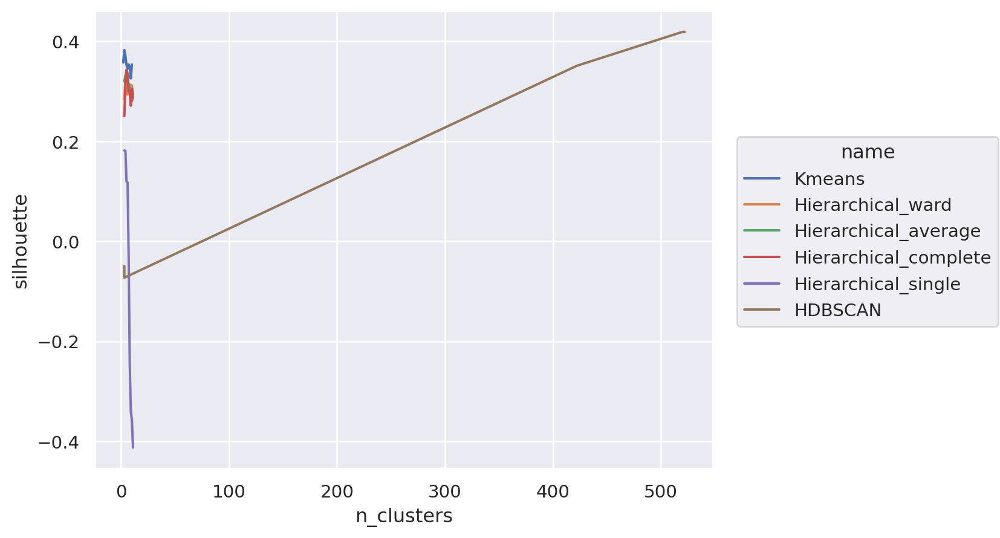

In [ ]:
so.Plot(df_clustering, x='n_clusters', y='silhouette', color='name').add(so.Line()).scale(color=so.Nominal())

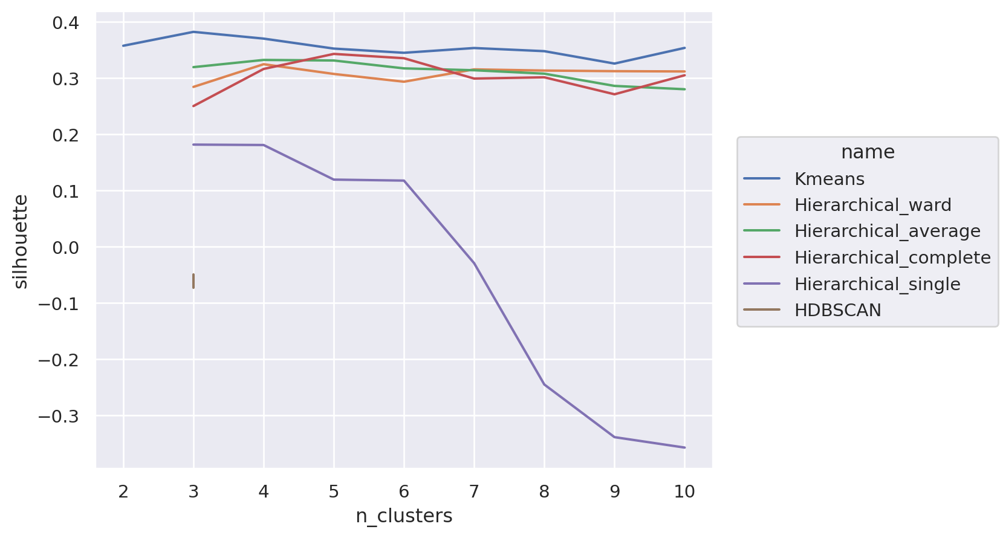

In [ ]:
so.Plot(df_clustering.filter(pl.col('n_clusters')<=10), x='n_clusters', y='silhouette', color='name').add(so.Line()).scale(color=so.Nominal())

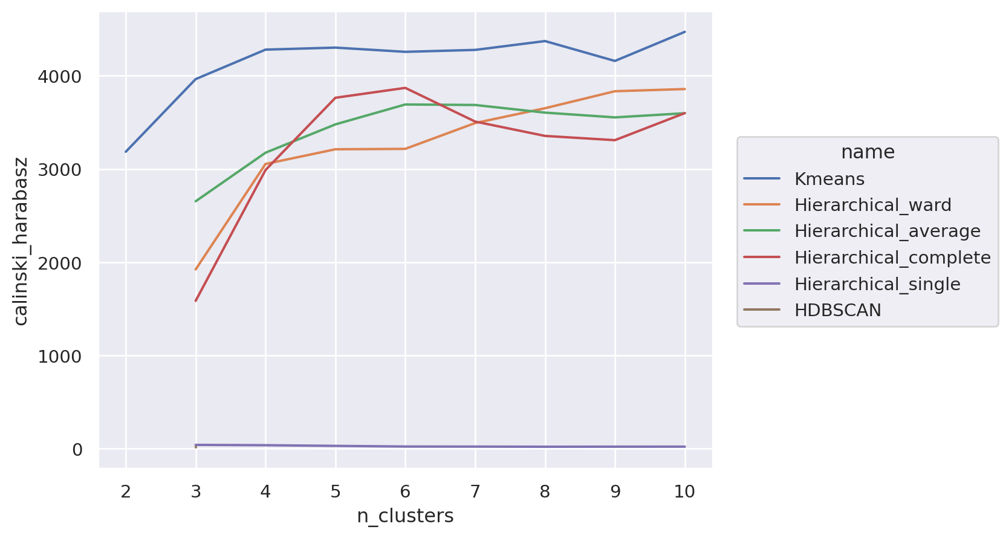

In [ ]:
so.Plot(df_clustering.filter(pl.col('n_clusters')<=10), x='n_clusters', y='calinski_harabasz', color='name').add(so.Line()).scale(color=so.Nominal())

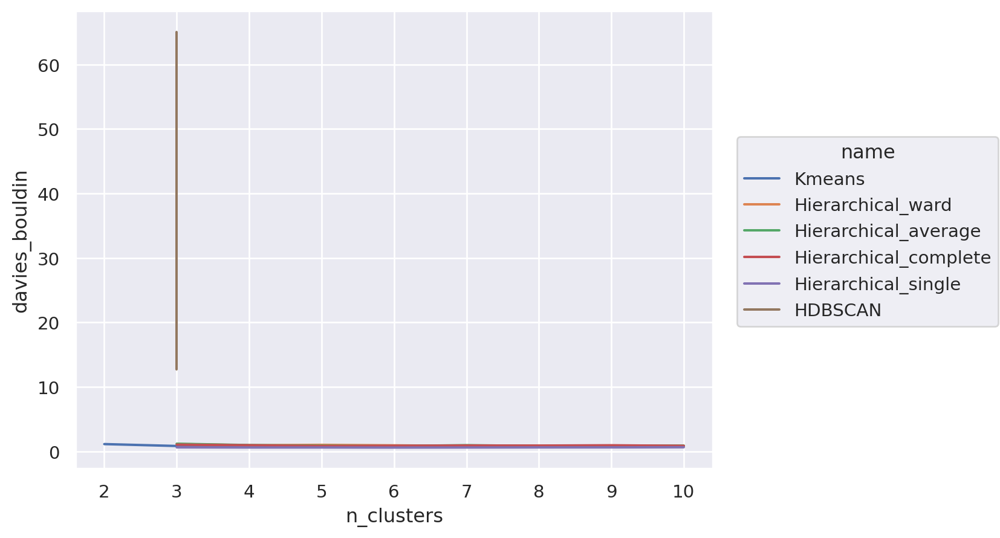

In [ ]:
so.Plot(df_clustering.filter(pl.col('n_clusters')<=10), x='n_clusters', y='davies_bouldin', color='name').add(so.Line()).scale(color=so.Nominal())


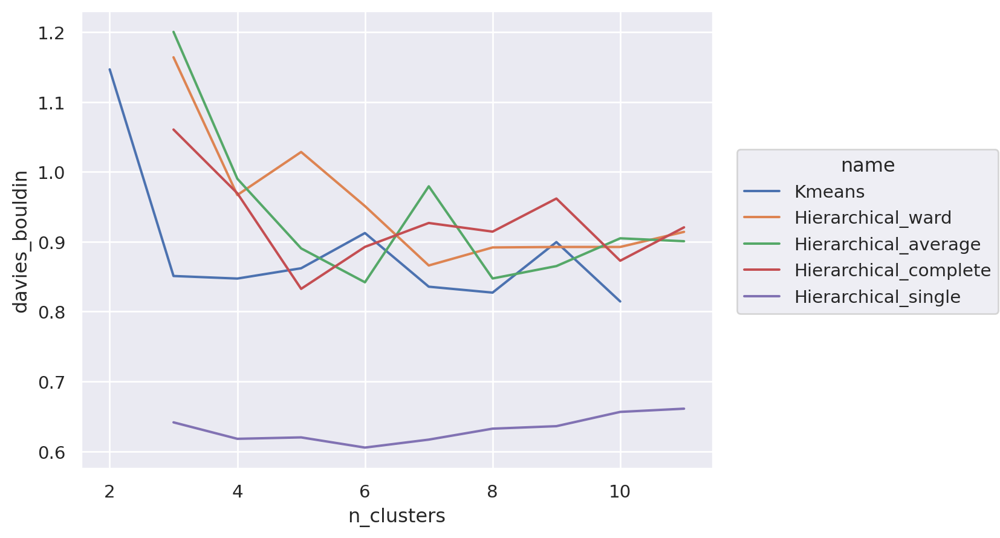

In [ ]:
so.Plot(df_clustering.filter(~(pl.col('name')=='HDBSCAN')), x='n_clusters', y='davies_bouldin', color='name').add(so.Line()).scale(color=so.Nominal())


---